# Monotonic KAN Transport Maps for L-SING
### Executable companion to `theory/kan_transport.tex`

**How to use this supplement:** Read the paper alongside Sections 1–7. Every theorem check and small numerical example runs on **Run all** (CPU or CUDA). Published benchmark artifacts load by default; set `BENCHMARK_MODE = "quick"` in the next control cell to actually train UMNN and KAN on the standard Gaussian, Butterfly and ovarian benchmarks plus hardware profiling. Set `"full"` to reproduce the longer suite (including the 40D projected baseline). Live timings and graph scores are hardware- and sample-dependent; quick scores are **not** the published full-run scores. Live outputs go into an isolated temporary checkout, never into tracked publication artifacts.

1. [Transport and architecture](#1-transport-and-architecture)
2. [Spline, monotonicity, and derivative checks](#2-spline-monotonicity-and-derivative-checks)
3. [Quadrature, profiling and training throughput](#3-quadrature-profiling-and-training-throughput)
4. [Gaussian graph recovery](#4-gaussian-graph-recovery-d10)
5. [Butterfly and scale modulation](#5-butterfly-and-scale-modulation-d10)
6. [TCGA ovarian cancer](#6-tcga-ovarian-cancer-d156)
7. [Synthesis](#7-synthesis)

## 1. Transport and architecture
L-SING learns conditional maps $S^k(x_{-k},\cdot)_\sharp\pi(x_k\mid x_{-k})=\mathcal N(0,1)$. Its empirical generalized precision entries are $\widehat\Omega_{jk}=N^{-1}\sum_i|T_{jk}(x^{(i)})|$ (not the signed average), with
$$T_{jk}=-S_jS_k-SS_{jk}+\frac{S_{jkk}S_k-S_{kk}S_{jk}}{S_k^2}.$$
UMNN implements the monotone map through 50-node numerical quadrature; SM-KAN replaces it with a monotonic spline core and separate conditioning scale and offset. The **only architecture image below** is the SM-KAN diagram included in the paper (`fig_sm_kan_liu`).

Device: cpu; precomputed results: results/kan_benchmarks (root: /home/stefano/lsing_sw)


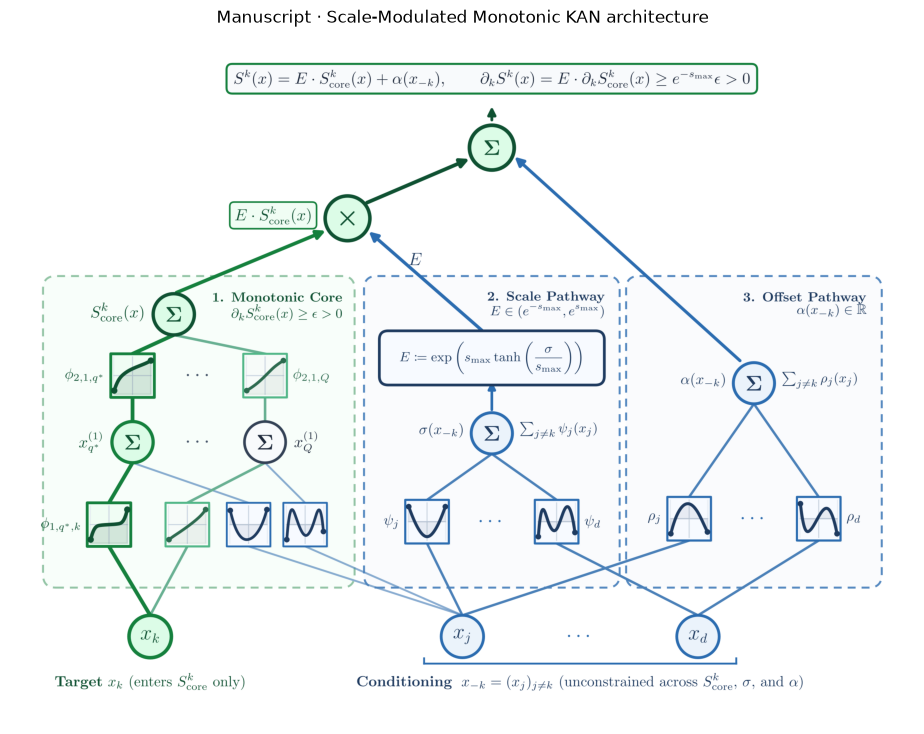

In [1]:
import os, sys, json, subprocess
from pathlib import Path
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
from IPython.display import display, Markdown

# Colab opens a GitHub notebook in /content, not in the repository checkout.
# Use the fork's current branch for the paper figures and committed results.
IN_COLAB = "google.colab" in sys.modules or "COLAB_RELEASE_TAG" in os.environ
REPO_ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents, Path("/content/lsing_sw"))
                  if (p / "theory/kan_transport.tex").is_file()), None)
if REPO_ROOT is None and IN_COLAB:
    REPO_ROOT = Path("/content/lsing_sw")
    if REPO_ROOT.exists():
        raise FileNotFoundError(f"Existing {REPO_ROOT} is not the expected repository; do not overwrite it")
    subprocess.run(["git", "clone", "--depth", "1", "--branch", "feat/monotonic-kan-transport",
                    "https://github.com/StefanoFochesatto/lsing_sw.git", str(REPO_ROOT)], check=True)
if REPO_ROOT is None:
    raise FileNotFoundError("Run from the repository root or notebooks/ directory (or open in Colab)")
REPO_ROOT = REPO_ROOT.resolve()
for path in (REPO_ROOT, REPO_ROOT / "src"):
    if str(path) not in sys.path: sys.path.insert(0, str(path))
RESULTS = REPO_ROOT / "results/kan_benchmarks"
# Published benchmark artifacts load unless BENCHMARK_MODE is changed below.
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}; precomputed results: results/kan_benchmarks (root: {REPO_ROOT})")

def paper_figure(name, caption, figsize=(13, 6)):
    path = REPO_ROOT / "theory/figures" / name
    if not path.is_file(): raise FileNotFoundError(path)
    fig, ax = plt.subplots(figsize=figsize)
    ax.imshow(mpimg.imread(path)); ax.axis("off")
    ax.set_title(caption)
    plt.show(); plt.close(fig)

paper_figure("fig_sm_kan_liu.png", "Manuscript · Scale-Modulated Monotonic KAN architecture", figsize=(12, 9))

### Reproduction controls
`"saved"` (default) runs the numerical examples and proof checks but loads publication benchmark JSON; no model training is hidden behind Run all. `"quick"` trains **both** UMNN and KAN at reduced sample size/epochs (a smoke test, not a reproduction of paper F1). `"full"` runs the full Gaussian, Butterfly and ovarian comparisons; ovarian UMNN can take tens of minutes and may exceed a free Colab session. The full 40D script uses a **one-row projected UMNN baseline**, not a measured full UMNN run. The scale-modulated Butterfly script trains SM-KAN only; the separate Butterfly sample-size script trains UMNN and additive KAN. CPU-only legacy scripts are labeled when used. Results/timings from a live run are displayed separately from the published CPU baseline.

In [2]:
import shutil, subprocess, tempfile, time

# Change this cell, then Run all. Do not edit the published JSONs to switch modes.
BENCHMARK_MODE = "saved"  # "saved", "quick", or "full"
if BENCHMARK_MODE not in ("saved", "quick", "full"):
    raise ValueError("BENCHMARK_MODE must be saved, quick or full")

LIVE_RESULTS = {}
BENCHMARK_ROOT = None
if BENCHMARK_MODE != "saved":
    # Scripts resolve their own repo root and write fixed filenames. Copy only the
    # code and source datasets into a temporary checkout to protect paper results.
    _scratch = tempfile.TemporaryDirectory(prefix="lsing_guide_")
    BENCHMARK_ROOT = Path(_scratch.name)
    for folder in ("models", "src", "benchmarks", "data"):
        shutil.copytree(REPO_ROOT / folder, BENCHMARK_ROOT / folder,
                        ignore=shutil.ignore_patterns("__pycache__", "*.pyc"))
    (BENCHMARK_ROOT / "results/kan_benchmarks").mkdir(parents=True)

    def run_benchmark(name, script, flags=(), output=None):
        cmd = [sys.executable, str(BENCHMARK_ROOT / "benchmarks" / script), *flags]
        log_path = BENCHMARK_ROOT / f"{name}.log"
        env = dict(os.environ, PYTHONPATH=os.pathsep.join((str(BENCHMARK_ROOT), str(BENCHMARK_ROOT / "src"))))
        print(f"Running {name} ({BENCHMARK_MODE}, {device.type}): {script} {' '.join(flags)}", flush=True)
        t0 = time.perf_counter()
        try:
            with log_path.open("w") as log:
                subprocess.run(cmd, cwd=BENCHMARK_ROOT, env=env, stdout=log,
                               stderr=subprocess.STDOUT, check=True, timeout=7200)
        except (subprocess.CalledProcessError, subprocess.TimeoutExpired) as exc:
            raise RuntimeError(f"{name} failed ({exc}); log tail:\n" +
                               "\n".join(log_path.read_text().splitlines()[-35:])) from exc
        print(f"  Finished in {time.perf_counter()-t0:.1f}s; log: {log_path}", flush=True)
        if output:
            result_path = BENCHMARK_ROOT / "results/kan_benchmarks" / output
            if not result_path.is_file(): raise FileNotFoundError(result_path)
            LIVE_RESULTS[output] = json.loads(result_path.read_text())

    _flags = ("--device", device.type) + (("--quick",) if BENCHMARK_MODE == "quick" else ())
    # These scripts train *both* UMNN and KAN on the same train/val/test split.
    run_benchmark("gaussian", "run_gaussian.py", _flags, "gaussian_benchmark.json")
    run_benchmark("butterfly", "run_butterfly_samples.py", _flags, "butterfly_sample_sizes.json")
    run_benchmark("ovarian", "run_ovarian_analysis.py", _flags, "ovarian_results.json")
    run_benchmark("hardware", "run_hardware_scaling.py", _flags, "hardware_scaling_results.json")
    if BENCHMARK_MODE == "full":
        print("The following legacy runners use CPU irrespective of the selected GPU.")
        run_benchmark("butterfly_sm", "run_scale_modulated_butterfly.py", output="scale_modulated_butterfly_results.json")
        run_benchmark("butterfly_40d", "run_butterfly_40d.py", output="butterfly_40d.json")
else:
    print("Saved mode: no training; examples and proof checks still execute.")

def result(name):
    if name in LIVE_RESULTS: return LIVE_RESULTS[name], f"LIVE {BENCHMARK_MODE.upper()} ({device.type})"
    return json.loads((RESULTS / name).read_text()), "SAVED ARTIFACT (not rerun; see dimension/provenance)"

Saved mode: no training; examples and proof checks still execute.


## 2. Spline, monotonicity, and derivative checks
**Lemma 4.1.** For a cubic spline $\phi(t)=\sum_m c_m B_{m,3}(t)$, de Boor differentiation gives a nonnegative quadratic-basis expansion in $c_{m+1}-c_m$. Choose
$$c_m=c_1+\sum_{r=1}^{m-1}(\operatorname{softplus}(\theta_r)+\delta_{\rm mono}).$$
This enforces positive interior slopes; $C^1$ linear extrapolation extends the boundary slopes to both tails. The following small, device-aware demonstration checks $[-8,8]$.

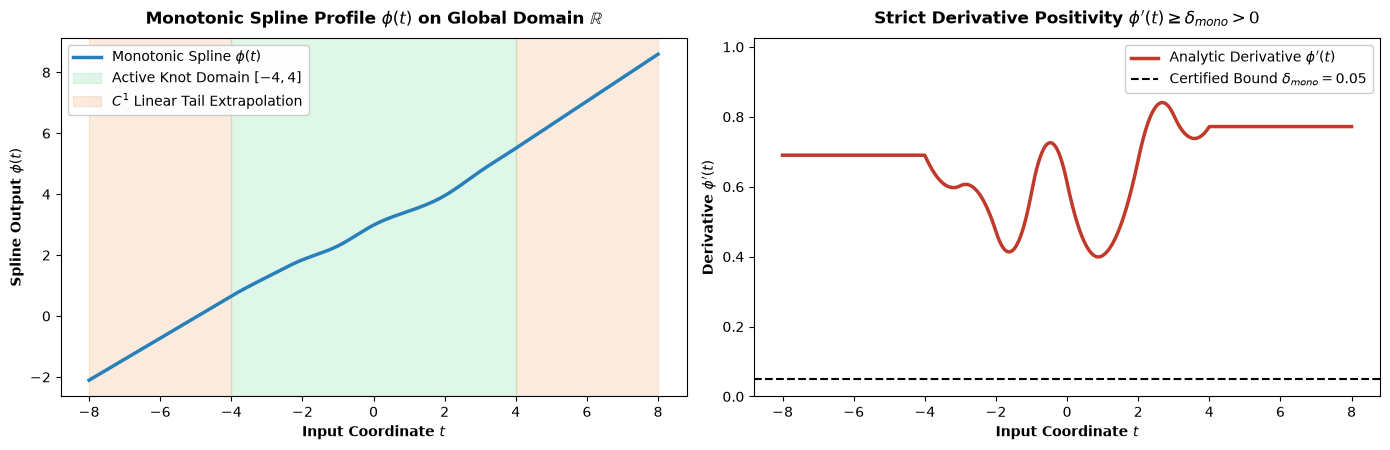

Lemma 4.1 Verification: Minimum spline derivative on [-8, 8] is 0.39922 > 0!


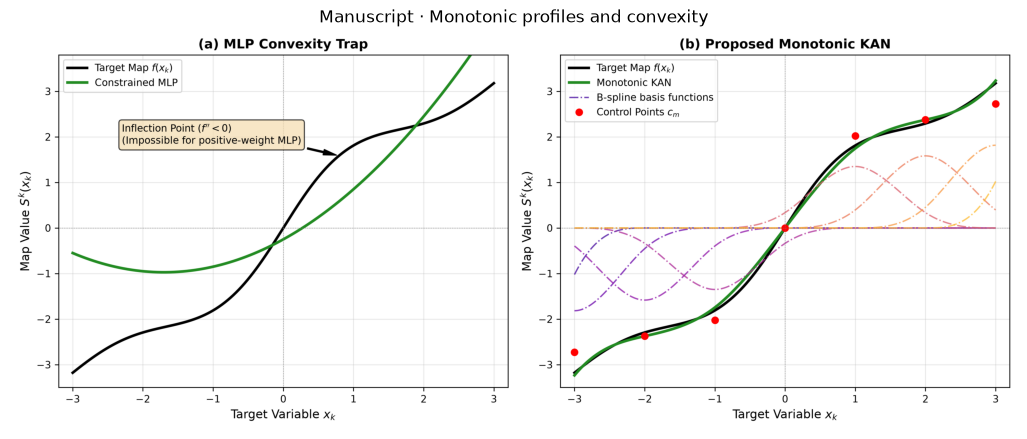

In [3]:
# Demonstration of Lemma 4.1: Cumulative Softplus & C^1 Linear Tail Extrapolation
from models.monotonic_kan import BSplineBasis

grid_min, grid_max = -4.0, 4.0
num_intervals = 8
spline_order = 3
grid = BSplineBasis.build_grid(grid_min, grid_max, num_intervals=num_intervals, degree=spline_order, device=device)
M = num_intervals + spline_order  # 11 control points
delta_mono = 0.05

# Random unconstrained parameters theta
torch.manual_seed(123)
theta = torch.randn(M, device=device)
c = torch.zeros(M, device=device)
c[0] = theta[0]
c[1:] = c[0] + torch.cumsum(torch.nn.functional.softplus(theta[1:]) + delta_mono, dim=0)

# Evaluate B-spline across interior and far extrapolation tails [-8, 8]
t_eval = torch.linspace(-8.0, 8.0, 1000, device=device).unsqueeze(1)
c_tensor = c.view(1, 1, M)

bases, d1, d2, d3 = BSplineBasis.eval_basis(t_eval, grid, spline_order)
phi = torch.sum(bases * c_tensor, dim=-1).squeeze().detach().cpu().numpy()
phi_p = torch.sum(d1 * c_tensor, dim=-1).squeeze().detach().cpu().numpy()
assert phi_p.min() >= delta_mono, "Spline monotonicity check failed"
t_cpu = t_eval.squeeze().detach().cpu().numpy()

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))

# Panel 1: Profile phi(t)
axes[0].plot(t_cpu, phi, color="#2980b9", lw=2.5, label=r"Monotonic Spline $\phi(t)$")
axes[0].axvspan(grid_min, grid_max, color="#2ecc71", alpha=0.15, label="Active Knot Domain $[-4, 4]$")
axes[0].axvspan(-8, grid_min, color="#e67e22", alpha=0.15, label=r"$C^1$ Linear Tail Extrapolation")
axes[0].axvspan(grid_max, 8, color="#e67e22", alpha=0.15)
axes[0].set_title(r"Monotonic Spline Profile $\phi(t)$ on Global Domain $\mathbb{R}$", fontweight="bold", pad=10)
axes[0].set_xlabel("Input Coordinate $t$", fontweight="bold")
axes[0].set_ylabel(r"Spline Output $\phi(t)$", fontweight="bold")
axes[0].legend(loc="upper left", framealpha=0.95)

# Panel 2: Derivative phi'(t)
axes[1].plot(t_cpu, phi_p, color="#c0392b", lw=2.5, label=r"Analytic Derivative $\phi'(t)$")
axes[1].axhline(delta_mono, color="black", linestyle="--", label=rf"Certified Bound $\delta_{{mono}} = {delta_mono}$")
axes[1].set_title(r"Strict Derivative Positivity $\phi'(t) \geq \delta_{mono} > 0$", fontweight="bold", pad=10)
axes[1].set_xlabel("Input Coordinate $t$", fontweight="bold")
axes[1].set_ylabel(r"Derivative $\phi'(t)$", fontweight="bold")
axes[1].set_ylim(0, max(phi_p) * 1.22)
axes[1].legend(loc="upper right", framealpha=0.95)

plt.tight_layout()
plt.show()
print(f"Lemma 4.1 Verification: Minimum spline derivative on [-8, 8] is {phi_p.min():.5f} > 0!")

# The convexity profile belongs with the spline foundations, not the architecture diagram.
paper_figure("fig2_monotonic_profiles_and_convexity.png", "Manuscript · Monotonic profiles and convexity")

### Active backbone: Theorem 4.4
For a deep core, the positive path $\mathcal P^*$ contributes $D_{\mathcal P^*}$ to $\partial_kS^k$. The next cell evaluates the **actual implementation** on both ordinary inputs and extrapolation tails. It checks dominance numerically; finite samples are illustrations, not substitutes for the theorem.

In [4]:
from models.monotonic_kan import MonotonicKANMap, ScaleModulatedKANMap

torch.manual_seed(321)
core = MonotonicKANMap(4, target_index=1, layers_hidden=[4, 5, 3, 1],
                       grid_size=8, eps_mono=0.05, dev=device).to(device)
core.randomize_parameters_(std=0.4, delta_std=0.6)
x_path = torch.linspace(-15, 15, 96, device=device).unsqueeze(1).repeat(1, 4)
with torch.no_grad():
    derivatives = core.compute_derivatives(x_path)
    slope = derivatives["S_k"].squeeze()
    path_slope = derivatives["S_k_backbone"].squeeze()
assert path_slope.min().item() > 0
assert (slope - path_slope).min().item() >= -1e-5
print(f"L={core.L}, active path={core.active_path}, device={device}")
print(f"min partial_k S^k={slope.min().item():.4g}, min D_P*={path_slope.min().item():.4g}, "
      f"min dominance margin={(slope-path_slope).min().item():.3g}")

L=3, active path=(1, 0, 0, 0), device=cpu
min partial_k S^k=6.645, min D_P*=0.1997, min dominance margin=6.24


### Exact analytic derivative implementation: Einstein recurrence
`compute_derivatives` composes spline first, second and third derivatives layer by layer with `torch.einsum`. Compare its precision integrand with a small float64 autodiff reference, *without* differentiating through UMNN quadrature. `compute_loss` uses $\tfrac12(S^k)^2-\log S_k$ plus the chosen sparsity penalty.

In [5]:
torch.manual_seed(42)
check_model = MonotonicKANMap(4, target_index=1, hidden_dim=4, grid_size=8,
                              dev=device).to(dtype=torch.float64, device=device)
check_model.randomize_parameters_(std=0.3, delta_std=0.5)
x_check = torch.randn(8, 4, dtype=torch.float64, device=device, requires_grad=True)
parts = check_model.compute_derivatives(x_check)
S, Sk = parts["out"], parts["S_k"]
analytic = (-parts["S_all"] * Sk - S * parts["S_jk"] +
            (parts["S_jkk"] * Sk - parts["S_kk"] * parts["S_jk"]) / Sk.square())
log_conditional = -0.5 * S.square() + torch.log(Sk)
grad_k = torch.autograd.grad(log_conditional.sum(), x_check, create_graph=True)[0][:, 1]
autograd_row = torch.autograd.grad(grad_k.sum(), x_check)[0]
error = (analytic[:, check_model.other_indices] - autograd_row[:, check_model.other_indices]).abs().max().item()
assert error < 1e-9, error
print(f"Precision integrand T_jk: max |analytic - float64 autograd| = {error:.2e}")
print("Both calculations are per-sample; unlike the analytic evaluation, this reference builds an autograd graph.")

# Precision extraction reuses analytic derivatives under no_grad; no quadrature graph.
with torch.no_grad():
    row = check_model.compute_precision_row(x_check.detach())
    check_model.penalty_type = "functional"
    functional = check_model.compute_regularization(check_model.compute_derivatives(x_check.detach())["S_all"])
    check_model.penalty_type = "coeff_group"
    coefficient_group = check_model.compute_regularization()
    check_model.penalty_type = "functional"
assert row.shape == (4,) and row[1] == 1.0
print(f"Analytic precision row={np.round(row, 3)}; functional penalty={functional.item():.3f}; "
      f"coefficient-group penalty={coefficient_group.item():.3f}")

Precision integrand T_jk: max |analytic - float64 autograd| = 1.55e-15
Both calculations are per-sample; unlike the analytic evaluation, this reference builds an autograd graph.
Analytic precision row=[0.599 1.    0.526 0.764]; functional penalty=3.024; coefficient-group penalty=5.723


### Scale modulation and Theorem 5.3
The implementation bounds $E=\exp(s_{\max}\tanh(\sigma_{\rm raw}/s_{\max}))>0$ and uses $S=ES_{\rm core}+\alpha$. The curvature ratio $\big(S_{jkk}S_k-S_{kk}S_{jk}\big)/S_k^2$ is invariant to the conditioning scale/offset. We check the *actual model* against its unmodulated core via the same analytic recurrence, with float64 tensors and a small batch.

In [6]:
torch.manual_seed(777)
sm = ScaleModulatedKANMap(4, target_index=1, hidden_dim=3, grid_size=8,
                          dev=device).to(dtype=torch.float64, device=device)
sm.randomize_parameters_(std=0.5, delta_std=0.6)
x_sm = torch.randn(12, 4, dtype=torch.float64, device=device)
with torch.no_grad():
    full = sm.compute_derivatives(x_sm)
    lhs = (full["S_jkk"] * full["S_k"] - full["S_kk"] * full["S_jk"]) / full["S_k"].square()
    acts, derivatives_per_layer = x_sm, []
    for layer in sm.core_layers:
        acts, p1, p2, p3 = layer.eval_splines_and_derivatives(acts)
        derivatives_per_layer.append((p1, p2, p3))
    A = torch.eye(4, dtype=x_sm.dtype, device=device).expand(len(x_sm), 4, 4)
    B, D = torch.zeros_like(A), torch.zeros_like(A)
    for p1, p2, p3 in derivatives_per_layer:
        Ak, Bk = A[:, :, 1], B[:, :, 1]
        A_next = torch.einsum('bai,bij->baj', p1, A)
        B_next = torch.einsum('bai,bi,bij->baj', p2, Ak, A) + torch.einsum('bai,bij->baj', p1, B)
        D_next = (torch.einsum('bai,bi,bij->baj', p3, Ak.square(), A) +
                  torch.einsum('bai,bij->baj', p2, Bk.unsqueeze(-1)*A + 2*Ak.unsqueeze(-1)*B) +
                  torch.einsum('bai,bij->baj', p1, D))
        A, B, D = A_next, B_next, D_next
    core_k, core_jk, core_jkk = A[:, :, 1], B.squeeze(1), D.squeeze(1)
    rhs = (core_jkk * core_k - core_jk[:, [1]] * core_jk) / core_k.square()
    residual = (lhs - rhs).abs().max().item()
    x_cond = x_sm[:, sm.other_indices]
    raw_scale = sm.scale_net(x_cond)
    E = torch.exp(sm.scale_bound * torch.tanh(raw_scale / sm.scale_bound))
    slope_error = (full["S_k"] - E * core_k).abs().max().item()
assert residual < 1e-9 and slope_error < 1e-9
print(f"E in [{E.min().item():.3f}, {E.max().item():.3f}], "
      f"max target-slope residual {slope_error:.2e}, curvature cancellation residual {residual:.2e}")

E in [0.615, 1.688], max target-slope residual 0.00e+00, curvature cancellation residual 4.44e-16


The transport pushforward is illustrated by the manuscript’s Figure 4 (target conditional → $S^k$ → standard normal).

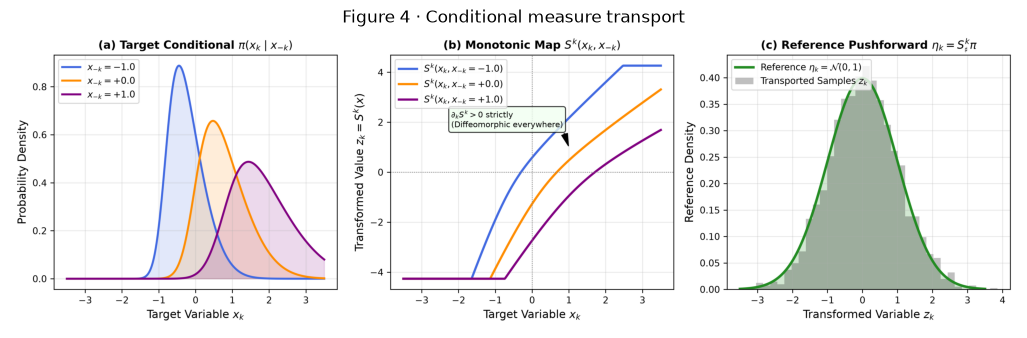

In [7]:
paper_figure("fig4_measure_transport_pushforward.png", "Figure 4 · Conditional measure transport")

### Conditional pushforward worked example (Figure 4 and Butterfly Figure 5)
In a Butterfly pair $X\sim\mathcal N(0,1)$, $Y=XW$ with $W\sim\mathcal N(0,1)$, the ideal conditional map for $X\ne0$ is $Z_Y=Y/|X|=\operatorname{sgn}(X)W$. The next cell uses the **committed benchmark test samples** (not an invented graph) to compare empirical moments before/after transport. It also exercises `ScaleModulatedKANMap.compute_loss` on a small batch; this is an untrained map, so we make no claim that its output is already Gaussian.

In [8]:
butterfly_samples = np.loadtxt(REPO_ROOT / "data/butterfly/bf_tst_10000_10d.txt", delimiter=",")[:2000, :2]
x_bf, y_bf = butterfly_samples[:, 0], butterfly_samples[:, 1]
mask = np.abs(x_bf) > 1e-8
z_bf = y_bf[mask] / np.abs(x_bf[mask])
print(f"Observed Y: mean={y_bf.mean():.3f}, variance={y_bf.var():.3f}; "
      f"ideal transported Z_Y: mean={z_bf.mean():.3f}, variance={z_bf.var():.3f}")
print(f"Ideal reference N(0,1) has mean=0, variance=1; {len(z_bf)} samples retained.")
example = ScaleModulatedKANMap(2, target_index=1, hidden_dim=3, grid_size=8, dev=device)
example_x = torch.as_tensor(butterfly_samples[:32], dtype=torch.float32, device=device)
loss, nll, regularizer = example.compute_loss(example_x, reg_value=0.01)
print(f"Untrained SM-KAN batch: NLL={nll.item():.3f}, sparsity penalty={regularizer.item():.3f}, "
      f"objective={loss.item():.3f} (not a fitted transport)")

Observed Y: mean=0.037, variance=0.983; ideal transported Z_Y: mean=0.024, variance=0.988
Ideal reference N(0,1) has mean=0, variance=1; 2000 samples retained.
Untrained SM-KAN batch: NLL=0.178, sparsity penalty=1.000, objective=0.188 (not a fitted transport)


## 3. Quadrature, profiling and training throughput
**Published CPU measurements** from `kan_benchmark_results.md` §2 (not live device timings). The display works on CUDA and CPU alike because it loads results rather than allocating large autodiff graphs. At $N=1{,}000$, KAN takes 0.059 s versus 5.898 s for UMNN (100.5×); at $N=2{,}000$, 0.127 s versus 10.558 s (83.1×). Analytic Einstein recurrence is 110.8× faster than `torch.func.hessian` vmap and builds no computation graph (0 MB graph memory).

| Published CPU metric | UMNN | KAN | Advantage |
|---|---:|---:|---:|
| Parameters / feature | 1,523 | 485 | 3.14× compact |
| Training samples/s | 33,011 | 104,591 | 3.17× |
| Precision extraction N=1,000 (s) | 5.898 | 0.059 | 100.5× |
| Precision extraction N=2,000 (s) | 10.558 | 0.127 | 83.1× |
| KAN analytic vs. torch.func.hessian vmap | — | 0.059 vs. 6.504 s | 110.8×; 0 MB graph memory |

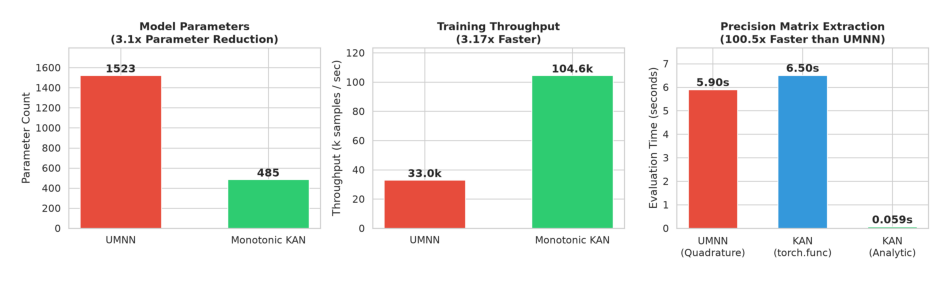

SAVED ARTIFACT (not rerun; see dimension/provenance) profiling: d=10, B=1000 training throughput: UMNN=13,060/s, KAN=41,125/s. Device-specific row latencies are not the published CPU comparison above.


In [9]:
with (RESULTS / "profiling.json").open() as f: profiling = json.load(f)
params = profiling["parameter_count"]
throughput = profiling["training_throughput"]
latency = profiling["precision_matrix_extraction"]
display(Markdown(f'''| Published CPU metric | UMNN | KAN | Advantage |
|---|---:|---:|---:|
| Parameters / feature | {params["umnn"]:,} | {params["monotonic_kan"]:,} | 3.14× compact |
| Training samples/s | {throughput["umnn_samples_per_sec"]:,.0f} | {throughput["kan_samples_per_sec"]:,.0f} | 3.17× |
| Precision extraction N=1,000 (s) | {latency["umnn_quadrature_seconds"]:.3f} | {latency["kan_analytic_chain_seconds"]:.3f} | 100.5× |
| Precision extraction N=2,000 (s) | 10.558 | 0.127 | 83.1× |
| KAN analytic vs. torch.func.hessian vmap | — | 0.059 vs. 6.504 s | 110.8×; 0 MB graph memory |'''))
# Render the committed publication-aligned chart; do not run hardware-specific timing here.
chart = RESULTS / "figures/chart_computational_speedup.png"
fig, ax = plt.subplots(figsize=(12, 5)); ax.imshow(mpimg.imread(chart)); ax.axis("off")
plt.show(); plt.close(fig)

if "hardware_scaling_results.json" in LIVE_RESULTS or (RESULTS / "hardware_scaling_results.json").exists():
    hw, hw_label = result("hardware_scaling_results.json")
    representative = next(r for r in hw["training_throughput"] if r["dim"] == 10 and r["batch_size"] == 1000)
    print(f"{hw_label} profiling: d=10, B=1000 training throughput: "
          f"UMNN={representative['umnn_samples_per_sec']:,.0f}/s, "
          f"KAN={representative['kan_samples_per_sec']:,.0f}/s. "
          "Device-specific row latencies are not the published CPU comparison above.")
else:
    print("No saved device-specific hardware profile. Select quick/full to measure on this machine.")

## 4. Gaussian graph recovery ($d=10$)
The true $\Omega=\Sigma^{-1}$ has four edges $(0,4),(2,6),(5,7),(6,9)$. At $\tau=0.20$ both methods have $F_1=1.000$, FPR = 0.000. At $\tau=0.10$ UMNN falls to $F_1=0.667$ (4 false positives; FPR = 0.098), while monotonic KAN retains $F_1=1.000$, FPR = 0.000. This is the tail-noise suppression result, not a new topology illustration.

Run `BENCHMARK_MODE="quick"` to train **both** architectures on 500 Gaussian samples and 200 evaluation samples. The printed quick F1 can differ substantially from the full $M=5{,}000$ paper result.

Gaussian matrix and F1: SAVED ARTIFACT (not rerun; see dimension/provenance)


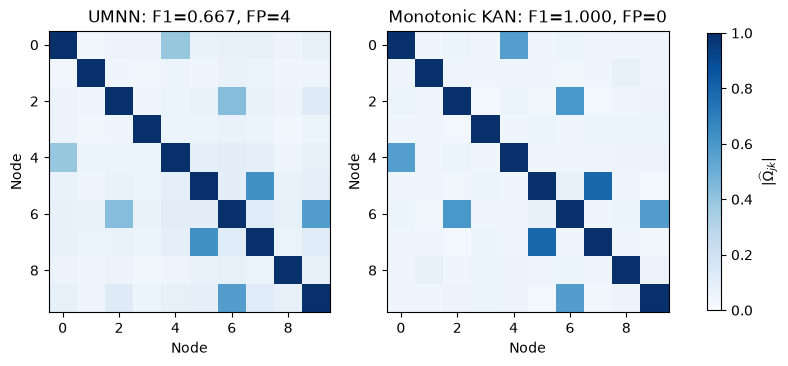

In [10]:
gaussian, gaussian_label = result("gaussian_benchmark.json")
print(f"Gaussian matrix and F1: {gaussian_label}")
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, key, title in zip(axes, ("UMNN", "MonotonicKAN_Functional"), ("UMNN", "Monotonic KAN")):
    matrix = np.abs(np.asarray(gaussian[key]["precision_matrix"]))
    image = ax.imshow(matrix, cmap="Blues", vmin=0, vmax=1)
    ax.set_title(f"{title}: F1={gaussian[key]['metrics']['0.1']['f1']:.3f}, FP={gaussian[key]['metrics']['0.1']['fp']}")
    ax.set_xlabel("Node"); ax.set_ylabel("Node")
fig.colorbar(image, ax=axes, label=r"$|\widehat{\Omega}_{jk}|$", shrink=.8)
plt.show(); plt.close(fig)

## 5. Butterfly and scale modulation ($d=10$)
Five independent pairs satisfy $X\sim\mathcal N(0,1)$, $Y=WX$, so $\operatorname{Var}(Y\mid X)=X^2$.

**Figure 5:** (a) bow-tie distribution; (b) ideal conditional transport $S^Y(Y;X)=Y/|X|$ for $X\in\{0.5,1,2\}$ (undefined at $X=0$, a null event); (c) isotropic $(Z_X,Z_Y)\sim\mathcal N(0,I_2)$; (d) SM-KAN precision with five connected pairs. The weakest true edge is 0.415 and strongest non-edge 0.112: $\Delta=0.303$, $F_1=1.000$, FPR = 0 across $\tau\in[0.15,0.40]$ ($M=5{,}000$). At $d=40$ (20 pairs, 780 candidate edges), full precision extraction takes **0.68 s**, versus projected UMNN **203.6 s** (299×).

The sample-size benchmark below compares UMNN against **additive** KAN. The SM-KAN result uses a separate script and is labeled accordingly; do not interpret cross-protocol timings as a controlled head-to-head measurement.

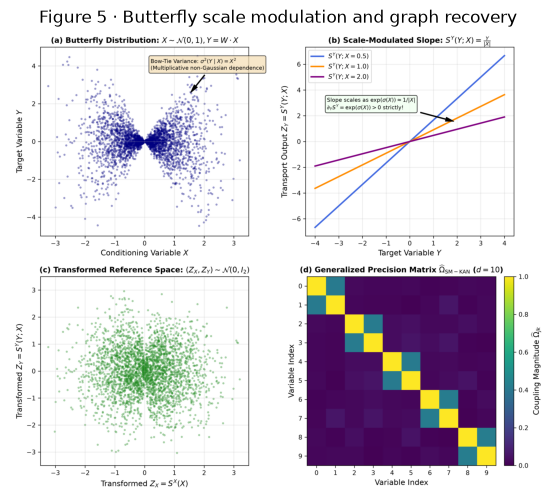

In [11]:
paper_figure("fig5_butterfly_scale_modulation.png", "Figure 5 · Butterfly scale modulation and graph recovery")

In [12]:
butterfly, bf_label = result("butterfly_sample_sizes.json")
print(f"Sample-size comparison: {bf_label}")
print("M     architecture             F1@0.10   FPR@0.10  precision eval (s)")
for M in sorted(butterfly, key=int):
    for key, label in (("UMNN", "UMNN"), ("MonotonicKAN_Functional", "Additive KAN")):
        if key not in butterfly[M]: continue
        entry = butterfly[M][key]
        scores = entry["metrics"]["0.1"]
        print(f"{M:5} {label:22} {scores['f1']:7.3f}   {scores['fpr']:7.3f}   {entry['eval_time_sec']:8.3f}")
sm_results, sm_label = result("scale_modulated_butterfly_results.json")
print(f"SM-KAN: {sm_label}; separate protocol, not paired quick-mode timings")
for M in sorted(sm_results, key=int):
    entry = sm_results[M]["ScaleModulatedKAN"]
    print(f"  M={M}: F1@0.1={entry['metrics']['0.1']['f1']:.3f}, "
          f"FPR@0.1={entry['metrics']['0.1']['fpr']:.3f}")

Sample-size comparison: SAVED ARTIFACT (not rerun; see dimension/provenance)
M     architecture             F1@0.10   FPR@0.10  precision eval (s)
500   UMNN                     0.278     0.650     12.501
500   Additive KAN             0.000     0.000      0.109
1000  UMNN                     0.357     0.450     12.470
1000  Additive KAN             0.000     0.000      0.114
5000  UMNN                     1.000     0.000     11.983
5000  Additive KAN             0.000     0.000      0.122
SM-KAN: SAVED ARTIFACT (not rerun; see dimension/provenance); separate protocol, not paired quick-mode timings
  M=1000: F1@0.1=0.256, FPR@0.1=0.725
  M=5000: F1@0.1=1.000, FPR@0.1=0.000


### High-dimensional Butterfly ($d=40$)
The 20 independent pairs occupy 20 of $\binom{40}{2}=780$ possible edges. The KAN script computes a full precision matrix; its UMNN number is extrapolated from **one evaluated row**, not a measured full-UMNN run. In `"full"` mode the legacy script runs on CPU even in a CUDA notebook.

In [13]:
d40, d40_label = result("butterfly_40d.json")
kan40 = d40.get("MonotonicKAN_Functional", d40.get("MonotonicKAN"))
um40 = d40["UMNN_Projected"]
print(f"{d40_label}: KAN measured full-matrix {kan40['eval_time_sec']:.3f}s; "
      f"UMNN projected {um40['eval_time_sec']:.1f}s (one-row extrapolation)")

SAVED ARTIFACT (not rerun; see dimension/provenance): KAN measured full-matrix 0.677s; UMNN projected 203.6s (one-row extrapolation)


## 6. TCGA ovarian cancer ($d=156$)
The manuscript reports $N=578$ patients (346 train, 115 validation, 117 test), $\binom{156}{2}=12{,}090$ interactions and **1.99 s** for the full SM-KAN precision matrix. The projected UMNN full-network time is ≈42 minutes (>1,200×); an alternate 260.1 s UMNN baseline versus 7.5 s KAN corresponds to ≈35×. These are different protocols, **not** the committed 12-gene quick-run timing.

The committed `ovarian_precision_matrix_full.txt` is the full $156\times156$ published matrix, copied from the repository's original full-run artifact without modifying the local 12-gene quick-run file. The heatmap and density curve below use **only** that full matrix. CTSE and EPCAM are candidate hubs in the sparse regime ($\tau=0.08,0.10$); the separate 12-gene quick-run rank concordance is Spearman $\rho=0.282$, not validation of clinical utility.

The full 156-gene heatmap below is the published artifact. A `quick` ovarian run trains 12 genes including CTSE/EPCAM and compares UMNN with SM-KAN on the same subset; it does not replace the 156-gene artifact.

In [14]:
ovarian_info, ov_label = result("ovarian_results.json")
print(f"{ov_label}: ovarian results for d={ovarian_info['num_genes']} genes")
if "umnn" in ovarian_info and "kan" in ovarian_info:
    um, ka = ovarian_info["umnn"], ovarian_info["kan"]
    print(f"UMNN train={um['train_time_sec']:.2f}s, eval={um['eval_time_sec']:.2f}s; "
          f"SM-KAN train={ka['train_time_sec']:.2f}s, eval={ka['eval_time_sec']:.2f}s")
    print(f"These timings describe the {ov_label} d={ovarian_info['num_genes']} network; do not compare with another sample size below.")
else:
    print(f"Published SM-KAN full-network eval={ovarian_info['eval_time_sec']:.2f}s; "
          "UMNN full-network time is a projection, not a paired live evaluation.")

SAVED ARTIFACT (not rerun; see dimension/provenance): ovarian results for d=12 genes
UMNN train=10.14s, eval=0.42s; SM-KAN train=4.18s, eval=0.22s
These timings describe the SAVED ARTIFACT (not rerun; see dimension/provenance) d=12 network; do not compare with another sample size below.


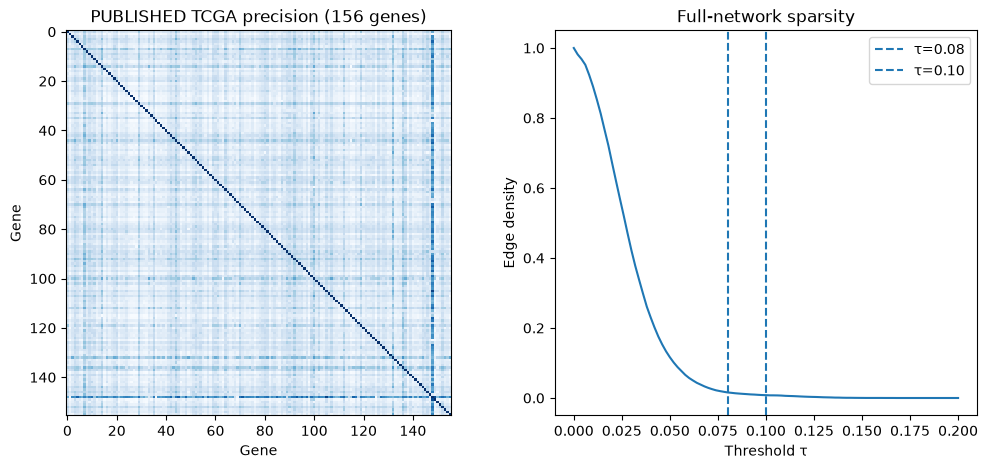

Separate saved 12-gene quick-run rank concordance: Spearman ρ=0.282


In [15]:
matrix_path = (BENCHMARK_ROOT / "results/kan_benchmarks/ovarian_precision_matrix.txt"
               if BENCHMARK_MODE == "full" else RESULTS / "ovarian_precision_matrix_full.txt")
matrix = np.loadtxt(matrix_path, delimiter=",")
if matrix.shape != (156, 156):
    raise ValueError(f"Expected a 156x156 full-network matrix, got {matrix.shape}")
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].imshow(np.abs(matrix), cmap="Blues", interpolation="nearest", vmin=0, vmax=.18)
axes[0].set(title=f"{'LIVE' if BENCHMARK_MODE == 'full' else 'PUBLISHED'} TCGA precision (156 genes)", xlabel="Gene", ylabel="Gene")
thresholds = np.linspace(0, .2, 101)
upper = np.abs(matrix[np.triu_indices(156, 1)])
axes[1].plot(thresholds, [(upper > t).mean() for t in thresholds])
for cutoff in (.08, .10):
    axes[1].axvline(cutoff, linestyle="--", label=f"τ={cutoff:.2f}")
axes[1].set(xlabel="Threshold τ", ylabel="Edge density", title="Full-network sparsity")
axes[1].legend()
plt.show(); plt.close(fig)
if BENCHMARK_MODE == "full":
    print("Full-network matrix from this live run; compare its values to the separate saved artifact explicitly.")
else:
    with (RESULTS / "ovarian_results.json").open() as f:
        ovarian_saved = json.load(f)
    if ovarian_saved.get("num_genes") == 12 and "comparison" in ovarian_saved:
        print(f"Separate saved 12-gene quick-run rank concordance: Spearman ρ={ovarian_saved['comparison']['spearman_correlation']:.3f}")
    else:
        print("Displayed published full-run matrix; the 12-gene quick-run Spearman ρ=0.282 is a separate protocol.")

## 7. Synthesis
| Metric / property | UMNN baseline | Scale-Modulated KAN | Advantage |
|:---|---:|---:|:---|
| Numerical quadrature | 50 nodes/sample | None | Exact forward pass |
| Precision evaluation $d=10$ | 10.56 s | **0.14 s** | **84×** |
| Precision evaluation $d=40$ | 203.6 s (projected) | **0.68 s** | **299×** |
| Precision evaluation $d=156$ ovarian | ≈42 min (projected) | **1.99 s** | **>1,200×** |
| Peak memory $d=10$ | 71.1 MB | **0.25 MB** | **284× lower** |
| Parameters per feature | 1,523 | **485** | **3.14× compact** |
| Training throughput | 33,011 samples/s | **104,591 samples/s** | **3.17×** |
| Gaussian $F_1$ at $\tau=0.10$ | 0.667 (4 FP) | **1.000 (0 FP)** | Perfect recovery |
| Butterfly $F_1$ at $M=5{,}000$ | 1.000 | **1.000** | Resolves heteroscedasticity |

**Three takeaways.** (1) Closed-form B-spline forward evaluation and `torch.einsum` recurrences compute first–third derivatives without quadrature. (2) Cumulative-softplus control points preserve $\partial_k S^k>0$ while allowing $\phi''$ to change sign. (3) $S^k(x)=\exp(\sigma(x_{-k}))S^k_{\rm core}(x)+\alpha(x_{-k})$ decouples location and scale for multiplicative non-Gaussian dependence.

**Discussion:** Published times are CPU measurements from different benchmark configurations; projections are marked explicitly. Ovarian heatmap and edge-density curve are computed from the committed full-run artifact, not the separate 12-gene quick run.

**Reproduction note:** The comparison table above is the manuscript baseline, not the output of a quick rerun. The live cells identify their mode, device, dimension and whether a UMNN value was measured or projected.